In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import numpy as np
warnings.filterwarnings('ignore')

In [51]:
df =  pd.read_csv("starbucks_drinkMenu_expanded.csv")
df.head()

,Beverage_category,Beverage,Beverage_prep,Calories,Total Fat (g),Trans Fat (g),Saturated Fat (g),Sodium (mg),Total Carbohydrates (g),Cholesterol (mg),Dietary Fibre (g),Sugars (g),Protein (g),Vitamin A (% DV),Vitamin C (% DV),Calcium (% DV),Iron (% DV),Caffeine (mg)
0,Coffee,Brewed Coffee,Short,3,0.1,0.0,0.0,0,5,0,0,0,0.3,0%,0%,0%,0%,175
1,Coffee,Brewed Coffee,Tall,4,0.1,0.0,0.0,0,10,0,0,0,0.5,0%,0%,0%,0%,260
2,Coffee,Brewed Coffee,Grande,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,0%,0%,330
3,Coffee,Brewed Coffee,Venti,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,2%,0%,410
4,Classic Espresso Drinks,Caffè Latte,Short Nonfat Milk,70,0.1,0.1,0.0,5,75,10,0,9,6.0,10%,0%,20%,0%,75


In [85]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 242 entries, 0 to 241
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Beverage_category          242 non-null    object 
 1   Beverage                   242 non-null    object 
 2   Beverage_prep              242 non-null    object 
 3   Calories                   242 non-null    int64  
 4    Total Fat (g)             242 non-null    float64
 5   Trans Fat (g)              242 non-null    float64
 6   Saturated Fat (g)          242 non-null    float64
 7    Sodium (mg)               242 non-null    int64  
 8    Total Carbohydrates (g)   242 non-null    int64  
 9   Cholesterol (mg)           242 non-null    int64  
 10   Dietary Fibre (g)         242 non-null    int64  
 11   Sugars (g)                242 non-null    int64  
 12   Protein (g)               242 non-null    float64
 13  Vitamin A (% DV)           242 non-null    float64

In [53]:
df[' Total Fat (g)'].unique()

array(['0.1', '3.5', '2.5', '0.2', '6', '4.5', '0.3', '7', '5', '0.4',
       '9', '1.5', '4', '2', '8', '3', '11', '0', '1', '10', '15', '13',
       '0.5', '3 2'], dtype=object)

In [54]:
df[' Total Fat (g)'] = pd.to_numeric(df[' Total Fat (g)'], errors='coerce')

In [55]:
df.shape

(242, 18)

In [81]:
(df.isnull().sum() / len(df)) * 100

Beverage_category            0.0
Beverage                     0.0
Beverage_prep                0.0
Calories                     0.0
 Total Fat (g)               0.0
Trans Fat (g)                0.0
Saturated Fat (g)            0.0
 Sodium (mg)                 0.0
 Total Carbohydrates (g)     0.0
Cholesterol (mg)             0.0
 Dietary Fibre (g)           0.0
 Sugars (g)                  0.0
 Protein (g)                 0.0
Vitamin A (% DV)             0.0
Vitamin C (% DV)             0.0
 Calcium (% DV)              0.0
Iron (% DV)                  0.0
Caffeine (mg)                0.0
dtype: float64

In [57]:
df.columns

Index(['Beverage_category', 'Beverage', 'Beverage_prep', 'Calories',
       ' Total Fat (g)', 'Trans Fat (g) ', 'Saturated Fat (g)', ' Sodium (mg)',
       ' Total Carbohydrates (g) ', 'Cholesterol (mg)', ' Dietary Fibre (g)',
       ' Sugars (g)', ' Protein (g) ', 'Vitamin A (% DV) ', 'Vitamin C (% DV)',
       ' Calcium (% DV) ', 'Iron (% DV) ', 'Caffeine (mg)'],
      dtype='object')

In [64]:
# The percentage values were converted to float by dividing by 100 (e.g., 75% → 0.75)

df['Iron (% DV) '] = df['Iron (% DV) '].str.replace('%', '').astype(float)

In [65]:
df.head()

,Beverage_category,Beverage,Beverage_prep,Calories,Total Fat (g),Trans Fat (g),Saturated Fat (g),Sodium (mg),Total Carbohydrates (g),Cholesterol (mg),Dietary Fibre (g),Sugars (g),Protein (g),Vitamin A (% DV),Vitamin C (% DV),Calcium (% DV),Iron (% DV),Caffeine (mg)
0,Coffee,Brewed Coffee,Short,3,0.1,0.0,0.0,0,5,0,0,0,0.3,0.0,0.0,0.0,0.0,175
1,Coffee,Brewed Coffee,Tall,4,0.1,0.0,0.0,0,10,0,0,0,0.5,0.0,0.0,0.0,0.0,260
2,Coffee,Brewed Coffee,Grande,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0.0,0.0,0.0,0.0,330
3,Coffee,Brewed Coffee,Venti,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0.0,0.0,2.0,0.0,410
4,Classic Espresso Drinks,Caffè Latte,Short Nonfat Milk,70,0.1,0.1,0.0,5,75,10,0,9,6.0,10.0,0.0,20.0,0.0,75


In [80]:
df['Caffeine (mg)'].unique()

array(['175', '260', '330', '410', '75', '150', '85', '95', '180', '225',
       '300', '10', '20', '25', '30', '0', 0, '50', '70', '120', '55',
       '80', '110', '165', '235', '90', '125', '170', '15', '130', '140',
       '100', '145', '65', '105'], dtype=object)

In [84]:
df['Caffeine (mg)'] = df['Caffeine (mg)'].astype(int)

In [79]:
df['Caffeine (mg)'] = df['Caffeine (mg)'].replace('varies', 0)

In [72]:
df['Caffeine (mg)'].fillna(0,inplace=True)

In [82]:
df.isnull().sum()

Beverage_category            0
Beverage                     0
Beverage_prep                0
Calories                     0
 Total Fat (g)               0
Trans Fat (g)                0
Saturated Fat (g)            0
 Sodium (mg)                 0
 Total Carbohydrates (g)     0
Cholesterol (mg)             0
 Dietary Fibre (g)           0
 Sugars (g)                  0
 Protein (g)                 0
Vitamin A (% DV)             0
Vitamin C (% DV)             0
 Calcium (% DV)              0
Iron (% DV)                  0
Caffeine (mg)                0
dtype: int64

In [86]:
df.to_excel("starbucks_data_cleaned.xlsx")

### analyzing

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import numpy as np
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_excel("starbucks_data_cleaned.xlsx")
df.head()

,Unnamed: 0,Beverage_category,Beverage,Beverage_prep,Calories,Total Fat (g),Trans Fat (g),Saturated Fat (g),Sodium (mg),Total Carbohydrates (g),Cholesterol (mg),Dietary Fibre (g),Sugars (g),Protein (g),Vitamin A (% DV),Vitamin C (% DV),Calcium (% DV),Iron (% DV),Caffeine (mg)
0,0,Coffee,Brewed Coffee,Short,3,0.1,0.0,0.0,0,5,0,0,0,0.3,0,0,0,0,175
1,1,Coffee,Brewed Coffee,Tall,4,0.1,0.0,0.0,0,10,0,0,0,0.5,0,0,0,0,260
2,2,Coffee,Brewed Coffee,Grande,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0,0,0,0,330
3,3,Coffee,Brewed Coffee,Venti,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0,0,2,0,410
4,4,Classic Espresso Drinks,Caffè Latte,Short Nonfat Milk,70,0.1,0.1,0.0,5,75,10,0,9,6.0,10,0,20,0,75


In [5]:
df.columns

Index(['Unnamed: 0', 'Beverage_category', 'Beverage', 'Beverage_prep',
       'Calories', 'Total Fat (g)', 'Trans Fat (g)', 'Saturated Fat (g)',
       'Sodium (mg)', 'Total Carbohydrates (g)', 'Cholesterol (mg)',
       'Dietary Fibre (g)', 'Sugars (g)', 'Protein (g)', 'Vitamin A (% DV)',
       'Vitamin C (% DV)', 'Calcium (% DV)', 'Iron (% DV)', 'Caffeine (mg)'],
      dtype='object')

In [4]:
# columns name unwanted spaces (extra space) remove option 
df.columns = df.columns.str.strip()

In [17]:
protien_cat = df.groupby("Beverage_category")["Protein (g)"].sum()
protien_cat

Beverage_category
Classic Espresso Drinks              503.8
Coffee                                 2.8
Frappuccino® Blended Coffee          152.0
Frappuccino® Blended Crème            52.0
Frappuccino® Light Blended Coffee     51.0
Shaken Iced Beverages                 24.2
Signature Espresso Drinks            395.0
Smoothies                            154.0
Tazo® Tea Drinks                     354.0
Name: Protein (g), dtype: float64

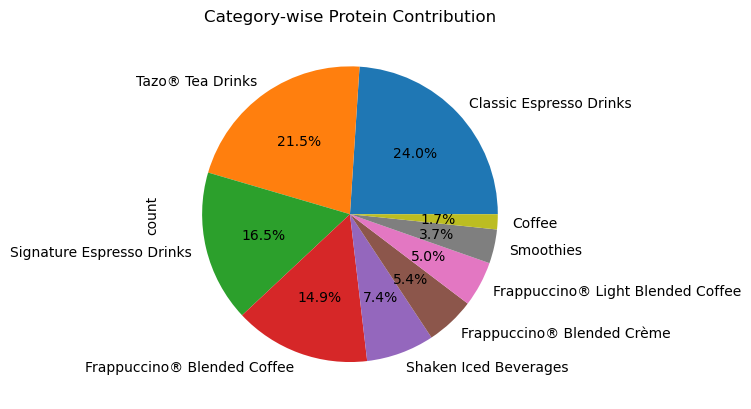

In [18]:
df["Beverage_category"].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title("Category-wise Protein Contribution")
plt.show()

In [32]:
calorie_cate = df.groupby("Beverage_category")['Calories'].max()
calorie_cate

Beverage_category
Classic Espresso Drinks              340
Coffee                                 5
Frappuccino® Blended Coffee          460
Frappuccino® Blended Crème           350
Frappuccino® Light Blended Coffee    290
Shaken Iced Beverages                190
Signature Espresso Drinks            510
Smoothies                            300
Tazo® Tea Drinks                     450
Name: Calories, dtype: int64

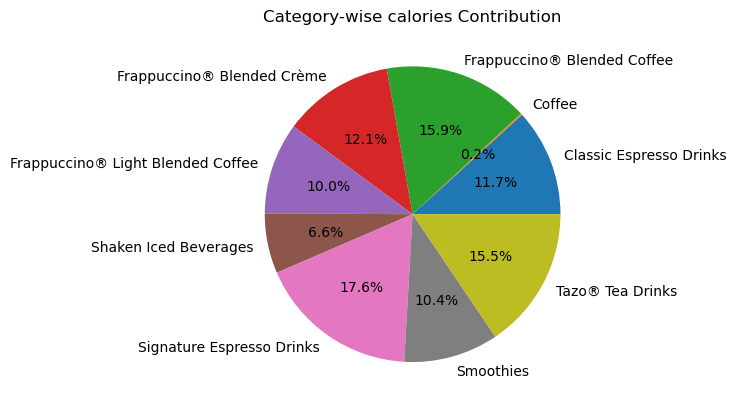

In [33]:
plt.pie(calorie_cate, labels=calorie_cate.index, autopct='%1.1f%%')
plt.title("Category-wise calories Contribution")
plt.show()

In [29]:
df.head(3)

,Beverage_category,Beverage,Beverage_prep,Calories,Total Fat (g),Trans Fat (g),Saturated Fat (g),Sodium (mg),Total Carbohydrates (g),Cholesterol (mg),Dietary Fibre (g),Sugars (g),Protein (g),Vitamin A (% DV),Vitamin C (% DV),Calcium (% DV),Iron (% DV),Caffeine (mg)
0,Coffee,Brewed Coffee,Short,3,0.1,0.0,0.0,0,5,0,0,0,0.3,0,0,0,0,175
1,Coffee,Brewed Coffee,Tall,4,0.1,0.0,0.0,0,10,0,0,0,0.5,0,0,0,0,260
2,Coffee,Brewed Coffee,Grande,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0,0,0,0,330


In [48]:
bevarage_cat = df['Beverage_category'].value_counts()
bevarage_cat

Beverage_category
Classic Espresso Drinks              58
Tazo® Tea Drinks                     52
Signature Espresso Drinks            40
Frappuccino® Blended Coffee          36
Shaken Iced Beverages                18
Frappuccino® Blended Crème           13
Frappuccino® Light Blended Coffee    12
Smoothies                             9
Coffee                                4
Name: count, dtype: int64

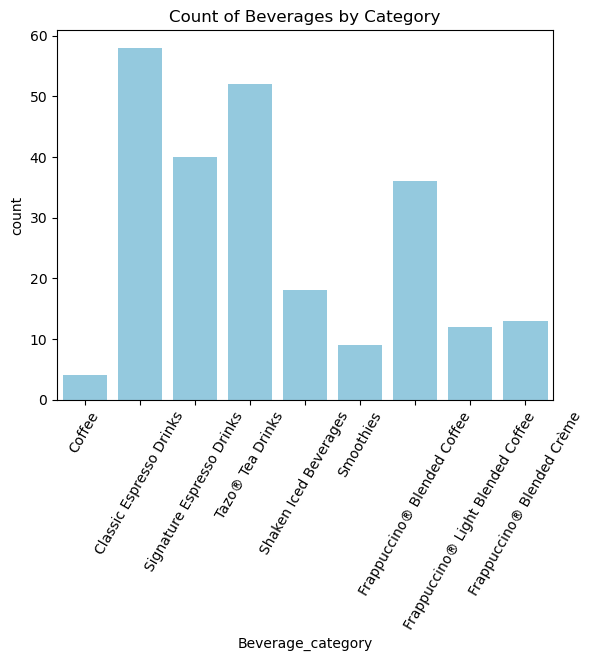

In [6]:
sns.countplot(x="Beverage_category",data=df,color="skyblue")
plt.title("Count of Beverages by Category")
plt.xticks(rotation=60)
plt.show()

In [45]:
bevarage_prep = df['Beverage_prep'].value_counts()
bevarage_prep

Beverage_prep
Soymilk               66
2% Milk               50
Grande Nonfat Milk    26
Tall Nonfat Milk      23
Venti Nonfat Milk     22
Whole Milk            16
Short Nonfat Milk     12
Tall                   7
Grande                 7
Venti                  7
Short                  4
Solo                   1
Doppio                 1
Name: count, dtype: int64

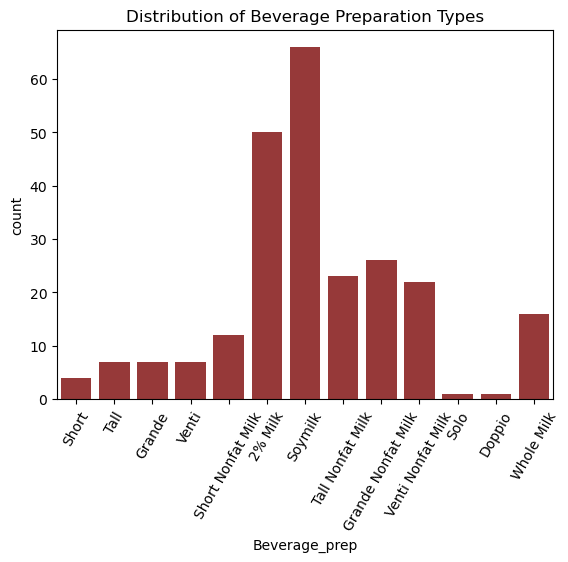

In [7]:
sns.countplot(x='Beverage_prep',data=df,color="brown")
plt.title("Distribution of Beverage Preparation Types")
plt.xticks(rotation=60)
plt.show()

In [59]:
df.head(2)

,Beverage_category,Beverage,Beverage_prep,Calories,Total Fat (g),Trans Fat (g),Saturated Fat (g),Sodium (mg),Total Carbohydrates (g),Cholesterol (mg),Dietary Fibre (g),Sugars (g),Protein (g),Vitamin A (% DV),Vitamin C (% DV),Calcium (% DV),Iron (% DV),Caffeine (mg)
0,Coffee,Brewed Coffee,Short,3,0.1,0.0,0.0,0,5,0,0,0,0.3,0,0,0,0,175
1,Coffee,Brewed Coffee,Tall,4,0.1,0.0,0.0,0,10,0,0,0,0.5,0,0,0,0,260


In [27]:
high_tans_fat = df.groupby("Beverage_category")["Trans Fat (g)"].max()
high_tans_fat

Beverage_category
Classic Espresso Drinks              6.0
Coffee                               0.0
Frappuccino® Blended Coffee          7.0
Frappuccino® Blended Crème           3.0
Frappuccino® Light Blended Coffee    4.0
Shaken Iced Beverages                1.0
Signature Espresso Drinks            9.0
Smoothies                            2.5
Tazo® Tea Drinks                     5.0
Name: Trans Fat (g), dtype: float64

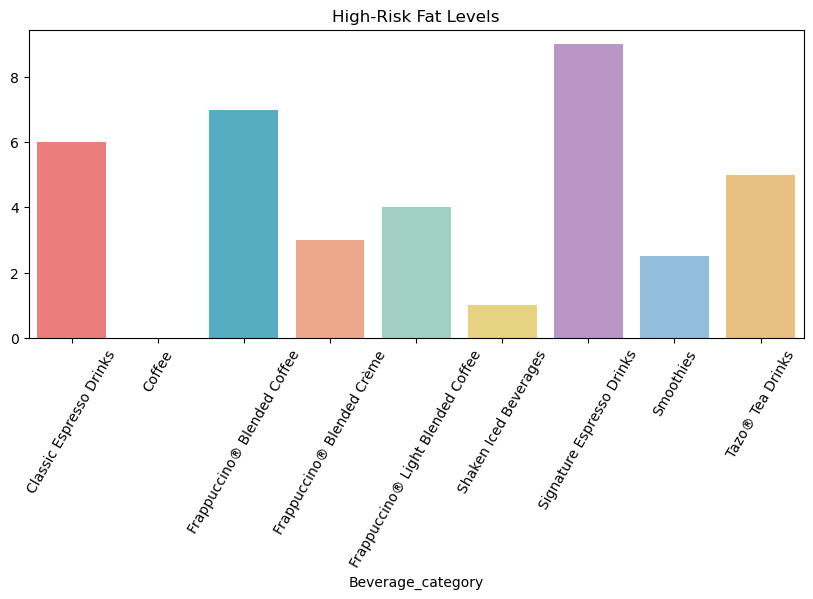

In [80]:
plt.figure(figsize=(10,4))
colors = [
    '#FF6B6B',  # red
    '#4ECDC4',  # teal
    '#45B7D1',  # blue
    '#FFA07A',  # light salmon
    '#98D8C8',  # mint
    '#F7DC6F',  # yellow
    '#BB8FCE',  # purple
    '#85C1E9',  # sky blue
    '#F8C471'   # orange
]
sns.barplot(x=high_tans_fat.index,y=high_tans_fat.values,palette=colors)
plt.xticks(rotation=60)
plt.title("High-Risk Fat Levels")
plt.show()

In [8]:
df.head()

,Unnamed: 0,Beverage_category,Beverage,Beverage_prep,Calories,Total Fat (g),Trans Fat (g),Saturated Fat (g),Sodium (mg),Total Carbohydrates (g),Cholesterol (mg),Dietary Fibre (g),Sugars (g),Protein (g),Vitamin A (% DV),Vitamin C (% DV),Calcium (% DV),Iron (% DV),Caffeine (mg)
0,0,Coffee,Brewed Coffee,Short,3,0.1,0.0,0.0,0,5,0,0,0,0.3,0,0,0,0,175
1,1,Coffee,Brewed Coffee,Tall,4,0.1,0.0,0.0,0,10,0,0,0,0.5,0,0,0,0,260
2,2,Coffee,Brewed Coffee,Grande,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0,0,0,0,330
3,3,Coffee,Brewed Coffee,Venti,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0,0,2,0,410
4,4,Classic Espresso Drinks,Caffè Latte,Short Nonfat Milk,70,0.1,0.1,0.0,5,75,10,0,9,6.0,10,0,20,0,75


In [54]:
high_caffeine = df.groupby("Beverage")["Caffeine (mg)"].max()
high_caffeine.nlargest(10)

Beverage
Brewed Coffee                                     410
Caffè Americano                                   300
Iced Brewed Coffee (With Classic Syrup)           235
Caffè Mocha (Without Whipped Cream)               180
Iced Brewed Coffee (With Milk & Classic Syrup)    170
Shaken Iced Tazo® Tea (With Classic Syrup)        170
Java Chip                                         165
Caffè Latte                                       150
Cappuccino                                        150
Caramel Macchiato                                 150
Name: Caffeine (mg), dtype: int64

In [52]:
largest_caffein = high_caffeine.nlargest(10)
largest_caffein

Beverage
Brewed Coffee                                     410
Caffè Americano                                   300
Iced Brewed Coffee (With Classic Syrup)           235
Caffè Mocha (Without Whipped Cream)               180
Iced Brewed Coffee (With Milk & Classic Syrup)    170
Shaken Iced Tazo® Tea (With Classic Syrup)        170
Java Chip                                         165
Caffè Latte                                       150
Cappuccino                                        150
Caramel Macchiato                                 150
Name: Caffeine (mg), dtype: int64

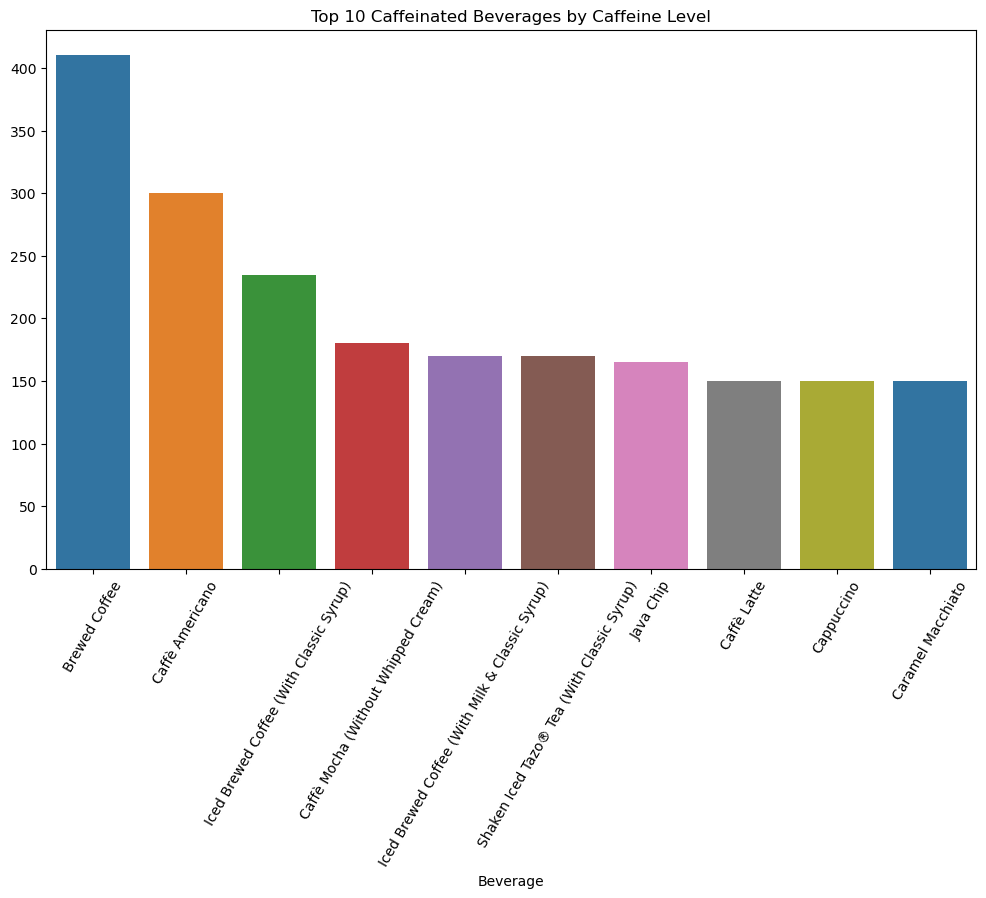

In [91]:
plt.figure(figsize=(12,7))
sns.barplot(x=largest_caffein.index,y=largest_caffein.values,color="purple",palette=colors)
colors = [
    '#1f77b4',  # blue
    '#ff7f0e',  # orange
    '#2ca02c',  # green
    '#d62728',  # red
    '#9467bd',  # purple
    '#8c564b',  # brown
    '#e377c2',  # pink
    '#7f7f7f',  # gray
    '#bcbd22'   # olive
]
plt.xticks(rotation=60)
plt.title("Top 10 Caffeinated Beverages by Caffeine Level")
plt.show()

In [86]:
sugar_count = df.groupby('Beverage_category')['Sugars (g)'].max()
sugar_count

Beverage_category
Classic Espresso Drinks              45
Coffee                                0
Frappuccino® Blended Coffee          84
Frappuccino® Blended Crème           69
Frappuccino® Light Blended Coffee    52
Shaken Iced Beverages                49
Signature Espresso Drinks            83
Smoothies                            41
Tazo® Tea Drinks                     71
Name: Sugars (g), dtype: int64

Text(0.5, 1.0, 'Beverage Categories with Highest Sugar Content')

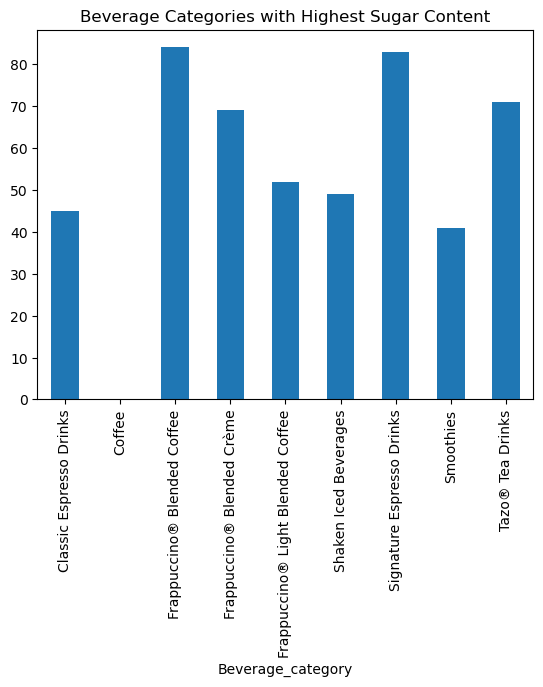

In [72]:
sugar_count.plot(kind='bar')
plt.title("Beverage Categories with Highest Sugar Content")

In [60]:
high_vitamin_c = df.groupby('Beverage_category')["Vitamin C (% DV)"].max()
high_vitamin_c

Beverage_category
Classic Espresso Drinks                2
Coffee                                 0
Frappuccino® Blended Coffee            0
Frappuccino® Blended Crème             8
Frappuccino® Light Blended Coffee      0
Shaken Iced Beverages                 20
Signature Espresso Drinks              4
Smoothies                            100
Tazo® Tea Drinks                      20
Name: Vitamin C (% DV), dtype: int64

In [62]:
vitamin_c_5 = high_vitamin_c.nlargest(5)
vitamin_c_5

Beverage_category
Smoothies                     100
Shaken Iced Beverages          20
Tazo® Tea Drinks               20
Frappuccino® Blended Crème      8
Signature Espresso Drinks       4
Name: Vitamin C (% DV), dtype: int64

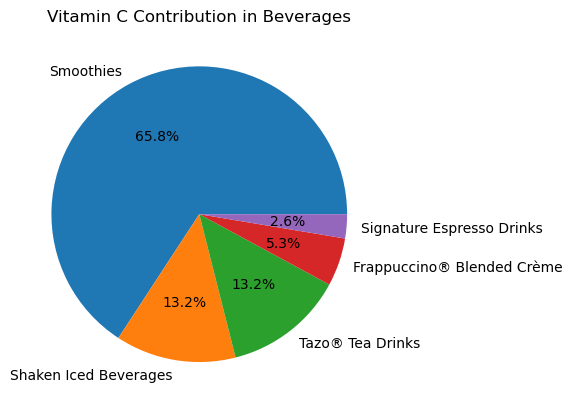

In [66]:
plt.pie(vitamin_c_5, labels=vitamin_c_5.index, autopct='%1.1f%%')
plt.title("Vitamin C Contribution in Beverages")
plt.show()

In [ ]:
Charts Description:  



                                   1  --  Category-wise Protein Contribution

-- This pie chart shows the distribution of beverages across different categories. 
-- Each slice represents a specific beverage category, and the size of the slice indicates its proportion in the dataset. 
-- The percentage labels on the chart help to easily compare how much each category contributes to the total. 
-- Larger slices mean that category has more beverages, while smaller slices indicate fewer entries.


                                   2   -- Category-wise calories Contribution 
                                   
-- This pie chart illustrates the maximum calorie values across different beverage categories. 
-- Each slice represents a category, and the size of the slice indicates the highest calorie value found within that category. 
-- The percentage labels show how much each category contributes relative to the total of these maximum values. 
-- Categories with larger slices have beverages with higher peak calorie content, while smaller slices represent categories with lower maximum calorie 
   values.

                                   3   --   Count of Beverages by Category"

-- This bar chart displays the number of beverages in each category. 
-- The x-axis represents different beverage categories, while the y-axis shows the count (frequency) of items in each category. 
-- Each bar indicates how many beverages belong to that specific category. 
-- Taller bars represent categories with a higher number of beverages, whereas shorter bars indicate fewer items. 
-- The rotated x-axis labels improve readability when category names are long.


                                  4   --  Distribution of Beverage Preparation Types


-- This count plot shows the number of beverages based on their preparation types. 
-- Each bar represents a specific preparation method, and the height of the bar indicates how many beverages fall under that category. 
-- The chart helps identify which preparation styles are most common and which are less frequently used. 
-- Taller bars indicate more popular preparation types, while shorter bars represent less common ones.


                                  5   --   High-Risk Fat Levels

-- This bar chart displays the maximum trans fat content found in each beverage category. 
-- Each bar represents a category, and its height indicates the highest amount of trans fat present in a single beverage within that category. 
-- The chart helps identify which categories contain drinks with potentially higher trans fat levels. 
-- Categories with taller bars may pose higher health risks due to elevated trans fat content, while shorter bars indicate relatively lower maximum 
   values.


                                 6  --  Top 10 Caffeinated Beverages by Caffeine Level
                                   
-- This bar chart shows the top 10 beverages with the highest caffeine levels. 
-- Each bar represents a specific beverage, and its height indicates the maximum amount of caffeine (in mg) found in that drink. 
-- The chart helps identify which beverages are the most caffeine-rich. 
-- Taller bars indicate higher caffeine content, making those drinks stronger in terms of stimulation, while shorter bars represent relatively lower 
   caffeine levels among the top 10.

                                7   --   Beverage Categories with Highest Sugar Content
 
-- This bar chart shows the highest sugar content found in each beverage category. 
-- Each bar represents a category, and its height indicates the maximum amount of sugar (in grams) present in a single beverage within that category. 
-- The chart helps identify which categories include drinks with very high sugar levels. 
-- Taller bars indicate categories that contain more sugar-heavy beverages, while shorter bars represent relatively lower maximum sugar values.

                               8   --   Vitamin C Contribution in Beverages

                               
-- This pie chart represents the top 5 beverage categories with the highest Vitamin C content. 
-- Each slice corresponds to a category, and its size indicates the maximum Vitamin C (% Daily Value) found in that category. 
-- The percentage labels show how much each category contributes relative to the total of these top values. 
-- Larger slices represent categories with beverages that provide higher Vitamin C levels, while smaller slices indicate comparatively lower values 
   among the top 5.
